---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

In [85]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---

## Group 19

- Raysha Erviandika Putra 13524050
- Mahmudia Kimdaro Amin 13524083
- Billie Bhaskara Wibawa 13524024
- Anindya Naufal Pinasthika 13524013
- Muhammad Fatih Irkham Mauludi 13524004

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Notebook ini berisi pengerjaan terkait tugas besar IF3170 Intelegensi Artifisial, yang dilakukan terkait algoritma-algoritma supervised learning.

## Overview

Pada tugas ini akan dilakukan perancangan dan implementasi beberapa varian algoritma supervised learning, dimana akan dilakukan eksperimen, dan analisis hasilnya juga.

## Aim

Tugas Besar II pada kuliah IF3170 Intelegensi Buatan bertujuan agar peserta kuliah mendapatkan wawasan tentang bagaimana cara mengimplementasikan dan mengevaluasi algoritma-algoritma supervised learning untuk menyelesaikan permasalahan berupa studi kasus yang relevan terhadap industri.

## Metric

Pemahaman terhadap algorithma supervised learning serta kemampuan menggunakannya untuk melakukan klasifikasi dataset.

## Dataset

Dataset berisi rekaman booking dari sebuah properti akomodasi tertentu. Informasi yang disediakan oleh dataset diantaranya yaitu daftar tamu, deskripsi penggunaan properti, deskripsi penginapan, saluran booking, harga booking, dan lain-lain. Target klasifikasi  utama yang ada pada dataset yaitu apakah tamu akan melakukan pembatalan booking atau tidak.

## Approach

Klasifikasi target kelas pada dataset akan dilakukan membuat model supervised learning menggunakan lima algoritma, yaitu Decision Tree Learning, K-Nearest-Neighbor, Support Vector Machine, Logistic Regression, dan Naive-Bayes. Model untuk klasifikasi akan dibuat dari algoritma yang diimplementasi dari scratch, tetapi akan tetapi dibandingkan dengan algoritma milik scikit-learn. Tentu diawal akan dilakukan tahapan-tahapan Exploratory Data Analysis terlebih dahulu.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [86]:
# %pip install -q numpy pandas matplotlib seaborn
# %pip install -e ./src

## Import Libraries

Import library custom yang akan digunakan pada keseluruhan notebok.

In [204]:
import os
import random

from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA


from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

Import custom library yang berisi algoritma supervised learning, hasil implementasi from scratch

In [244]:
from kagglemethis.DTL import DTL
from kagglemethis.LogisticRegression import LogisticRegression as LR
from kagglemethis.NaiveBayes import NaiveBayes
from kagglemethis.KNN import KNN
from kagglemethis.SVM import SVC as CustomSVC, plot_decision_boundary

## Settings

Buat settings terkait parameter-parameter dan path yang digunakan.

In [89]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

Tambahkan seeding sehingga hasil akhir dapat direproduksi dengan baik dan deterministik. Tanpa seed maka hasil dapat berubah-rubah dan sulit dikontrol.

In [90]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Load dataset kompetisi, perhatikan bahwa kolom `id` dianggap sebagai teks walaupun beberapa nilai terlihat seperti numerik.

In [91]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding dilakukan pertama dengan melihat berbagai atribut dan karakteristik dataset sehingga pemrosesan lanjutan dan pembuatan model dapat dilakukan dengan baik.

## Describe Data

Deskripsi ukuran, tipe data, dan karakteristik tiap kolom atribut.

In [92]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)


Training shape: (27373, 19)
Testing shape: (6844, 18)


In [93]:
print("============= Overview data training ===========")
display(train_df.head())

print("=========== Overview karakteristik data training ===========")
train_df.info()

print("=========== Overview statistik data training ===========")
display(train_df.describe(include="all").T)

print("=========== Overview kelas target ===========")
display(
    train_df["is_canceled"]
    .value_counts()
    .rename_axis("is_canceled")
    .reset_index(name="count")
)

============= Overview data training ===========


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


=========== Overview karakteristik data training ===========
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returnin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27373,27373,57152f82,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_adults,26564.0,NaN,NaN,NaN,1.845242,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,NaN,NaN,NaN,0.117388,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,NaN,NaN,NaN,0.814854,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,NaN,NaN,NaN,2.206517,1.421603,0.0,1.0,2.0,3.0,17.0
meal_package,25613,4,Breakfast,19654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
needs_parking,26291.0,NaN,NaN,NaN,0.0302,0.171142,0.0,0.0,0.0,0.0,1.0
room_category,26371,7,Type B,20447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_before_arrival,26250.0,NaN,NaN,NaN,85.379429,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,NaN,NaN,NaN,2023.820115,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


=========== Overview kelas target ===========


,is_canceled,count
0,0,18404
1,1,8969


## Explore Data

This part covers distributions and relationships between attributes.


=========== Visualisasi distribusi kelas target ===========


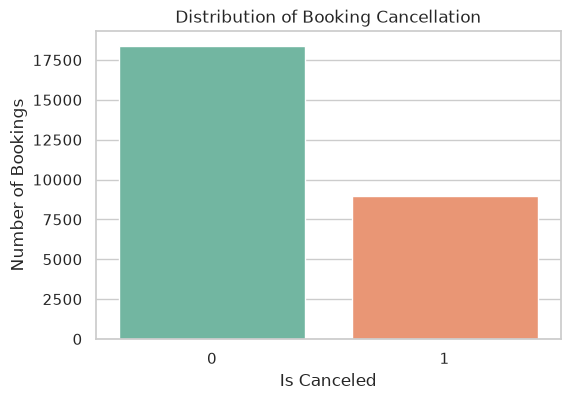


=========== Persentase kelas target ===========
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64

=========== Visualisasi atribut numerik ===========


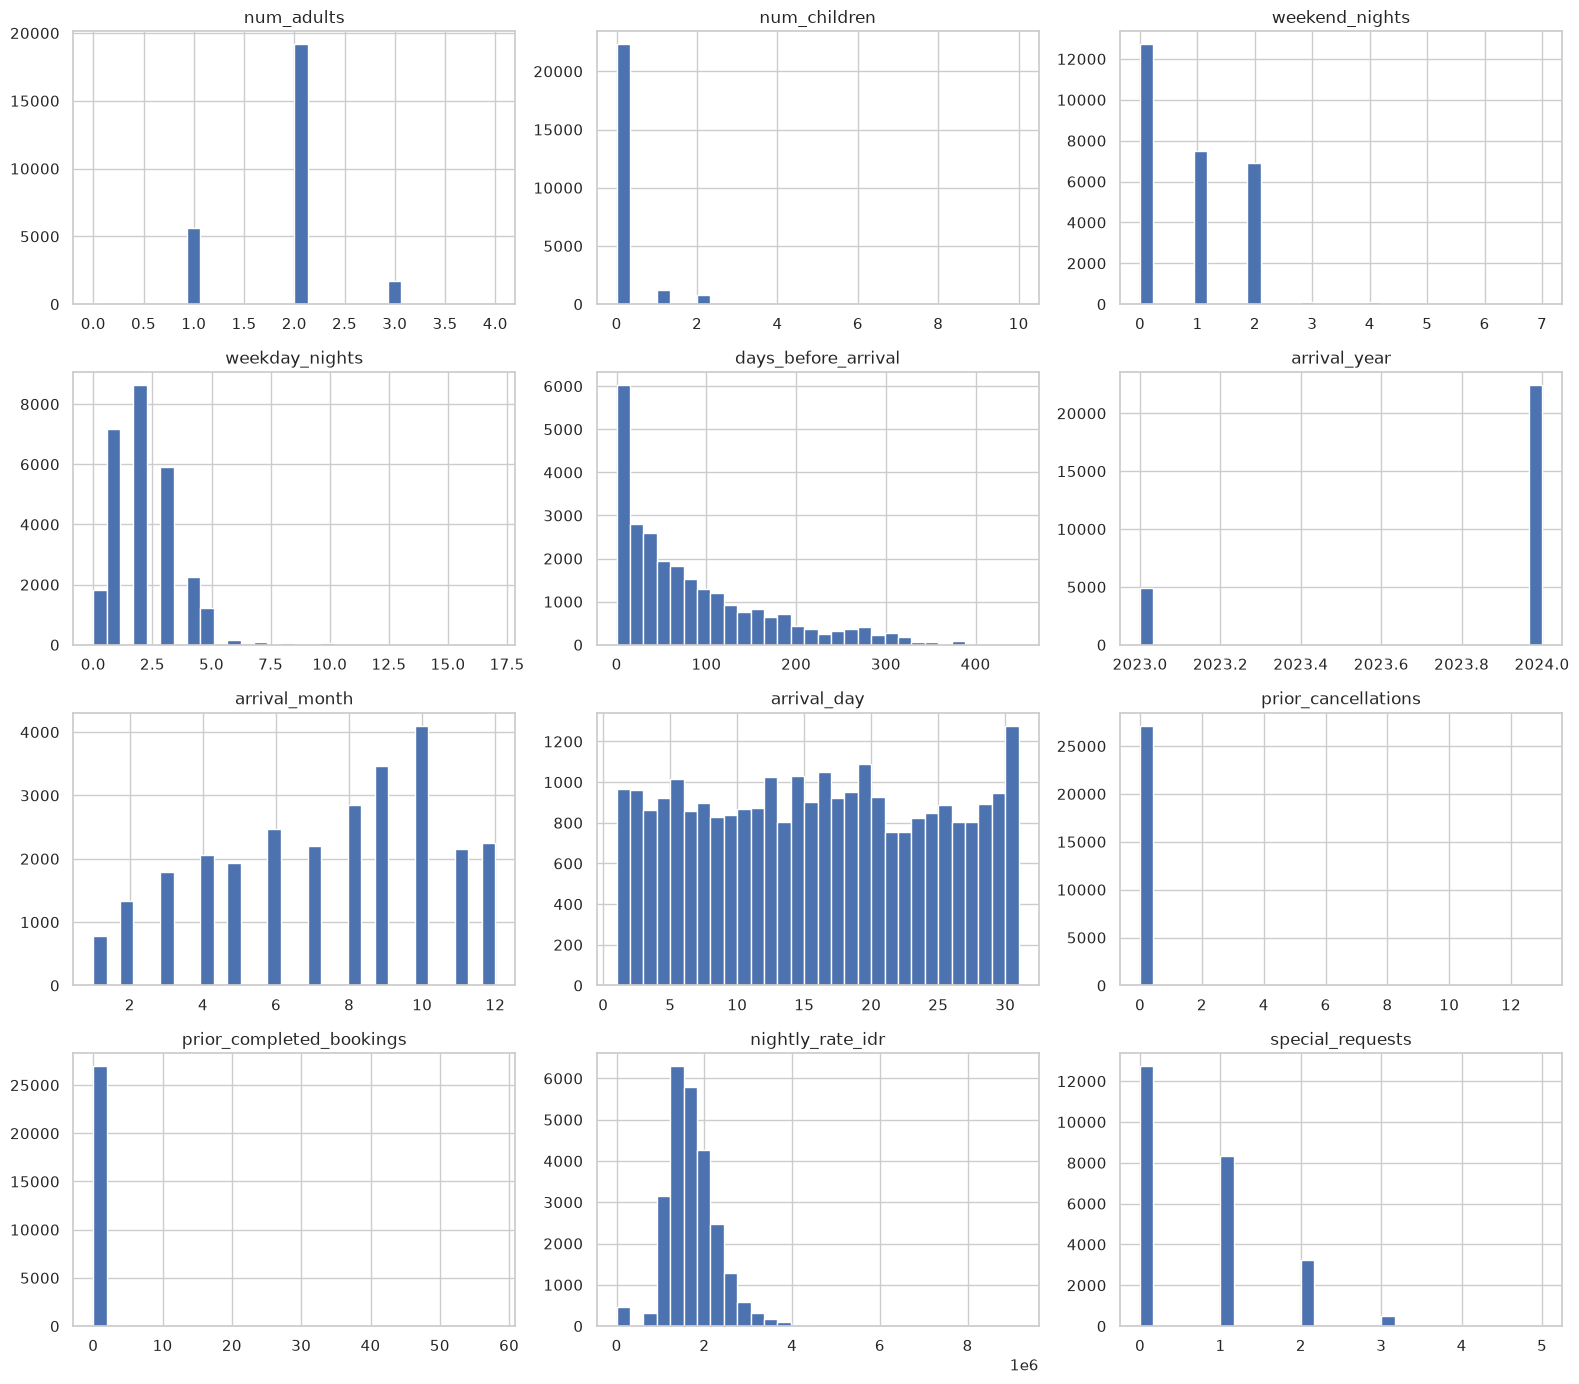

In [94]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="is_canceled",
    hue="is_canceled",
    palette="Set2",
    legend=False,
    ax=ax
)

ax.set_title("Distribution of Booking Cancellation")
ax.set_xlabel("Is Canceled")
ax.set_ylabel("Number of Bookings")

print("\n=========== Visualisasi distribusi kelas target ===========")
plt.show()


print("\n=========== Persentase kelas target ===========")
print(
    train_df["is_canceled"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

numeric_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

print("\n=========== Visualisasi atribut numerik ===========")
train_df[numeric_cols].hist(
    bins=30,
    figsize=(16, 14),
    layout=(4, 3)
)
plt.tight_layout()
plt.show()

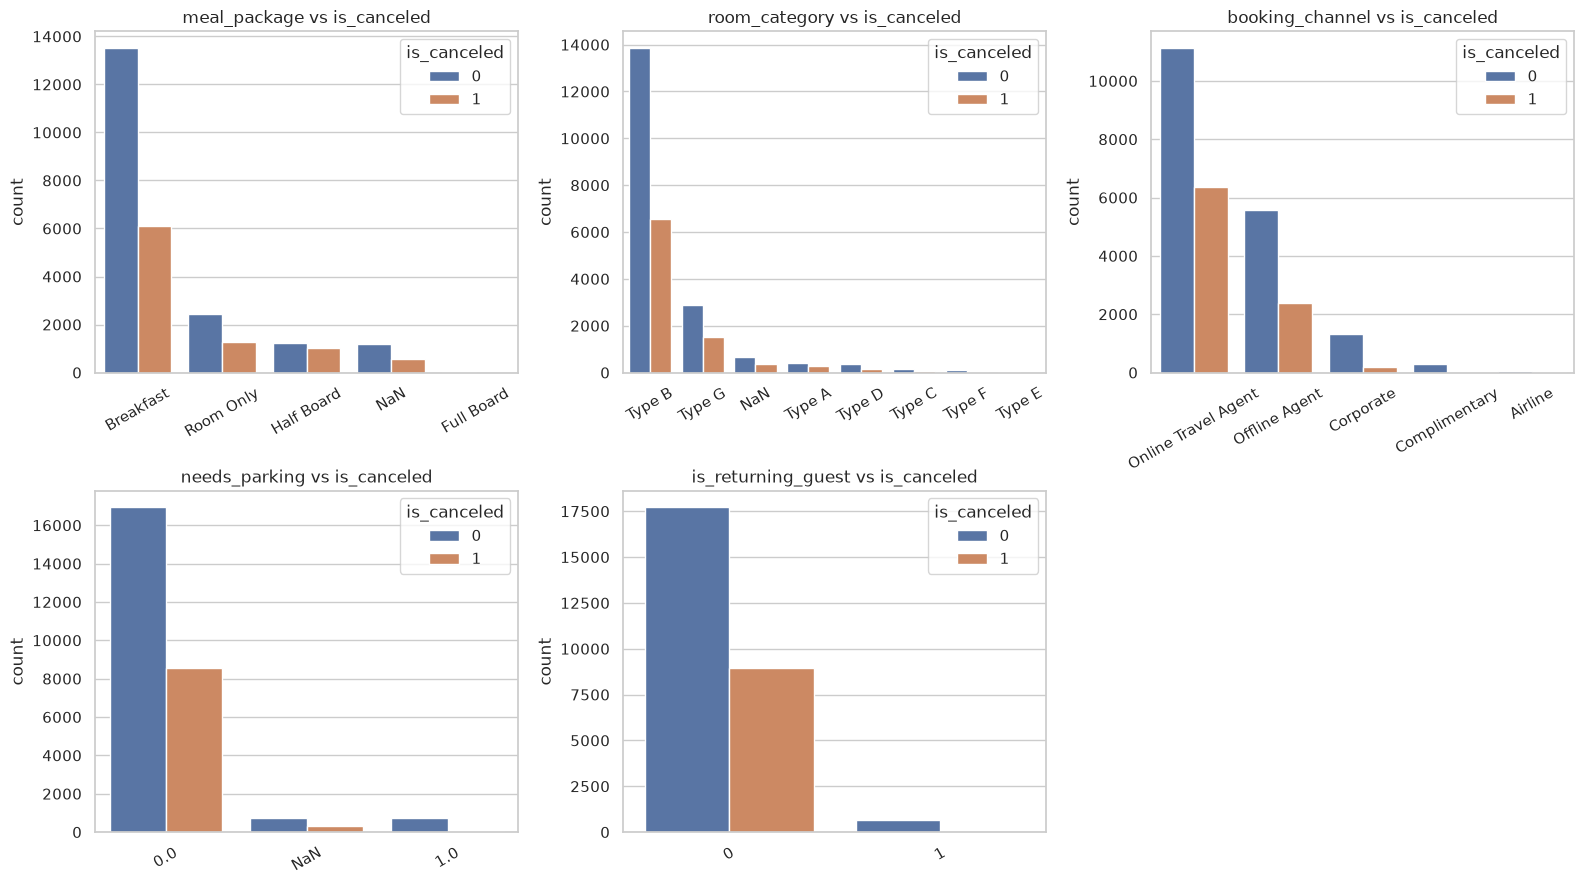

In [95]:
cat_cols = [
    "meal_package",
    "room_category",
    "booking_channel",
    "needs_parking",
    "is_returning_guest",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    plot_series = train_df[col].astype(str).fillna("NaN").astype(str)

    sns.countplot(
        x=plot_series,
        hue=train_df["is_canceled"],
        order=plot_series.value_counts().index,
        ax=axes[i],
    )
    axes[i].set_title(f"{col} vs is_canceled")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


=========== Visualisasi persentase melakukan cancel berdasarkan atribut kategorikal lainnya ===========


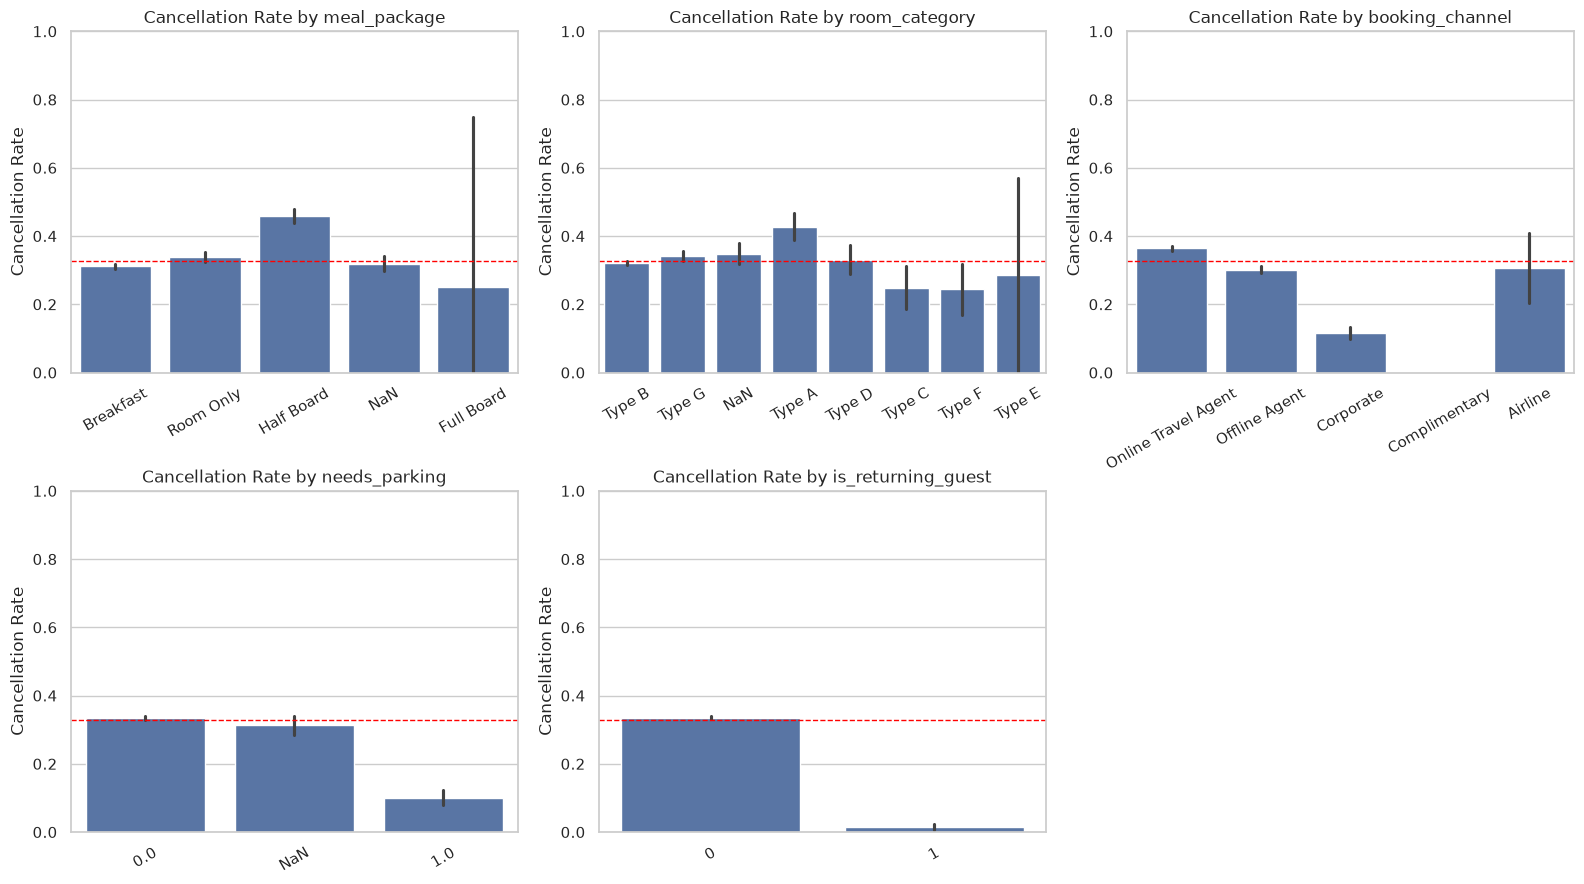

In [96]:
print("\n=========== Visualisasi persentase melakukan cancel berdasarkan atribut kategorikal lainnya ===========")

cat_cols = [
    "meal_package",
    "room_category",
    "booking_channel",
    "needs_parking",
    "is_returning_guest",
]

baseline_rate = train_df["is_canceled"].mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    plot_series = train_df[col].astype(str).fillna("NaN").astype(str)
    order = plot_series.value_counts().index

    sns.barplot(
        x=plot_series,
        y=train_df["is_canceled"],
        order=order,
        ax=axes[i],
    )
    axes[i].axhline(baseline_rate, color="red", linestyle="--", linewidth=1, label="Overall Avg")
    axes[i].set_title(f"Cancellation Rate by {col}")
    axes[i].set_ylabel("Cancellation Rate")
    axes[i].set_xlabel("")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()


=========== Distribusi outlier berdasarkan kelas target ===========


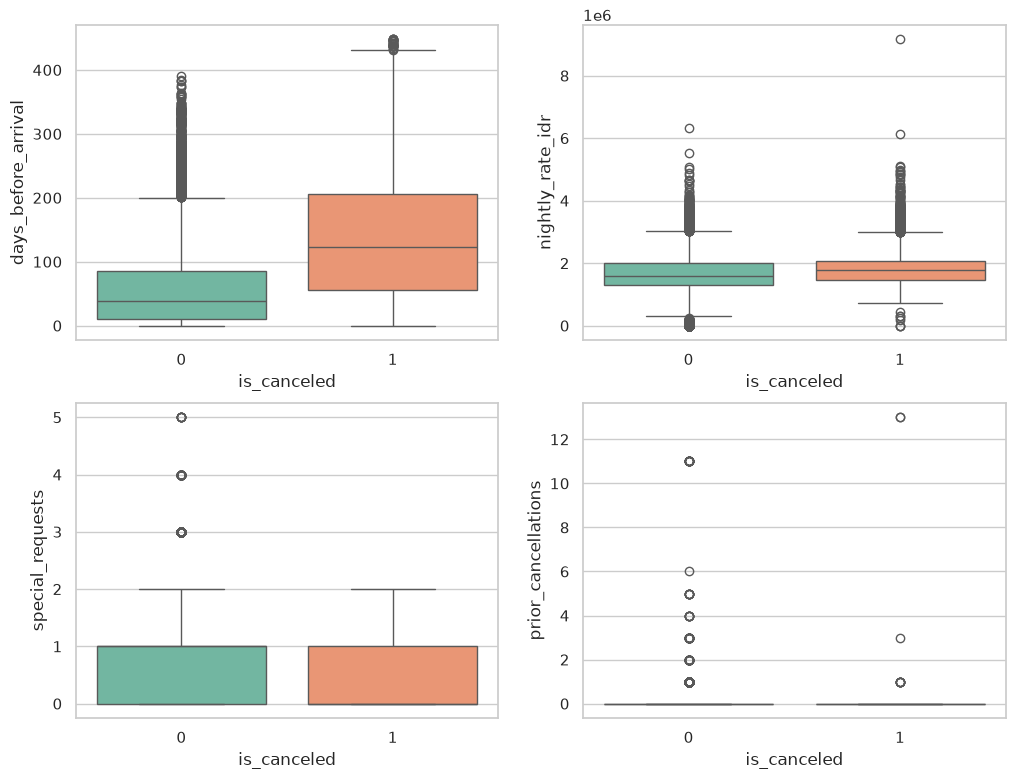

In [97]:
selected_cols = [
    "days_before_arrival",
    "nightly_rate_idr",
    "special_requests",
    "prior_cancellations"
]

print("\n=========== Distribusi outlier berdasarkan kelas target ===========")
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, selected_cols):
    sns.boxplot(
        data=train_df,
        x="is_canceled",
        y=col,
        hue="is_canceled",
        palette="Set2",
        legend=False,
        showfliers=True,
        ax=ax
    )

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [98]:
missing = pd.DataFrame({
    "count": train_df.isna().sum(),
    "percentage": train_df.isna().mean() * 100
}).sort_values("count", ascending=False)

print("\n=========== Statistik missing value per-atribut ===========")
display(missing)

print("\n=========== Statistik row duplicate ===========")
print("Duplicate IDs:", train_df["id"].duplicated().sum())
print("Duplicate rows:", train_df.duplicated().sum())

feature_cols = train_df.columns.drop("id")
print("Duplicates excluding ID:", train_df.duplicated(subset=feature_cols).sum())

binary_cols = [
    "needs_parking",
    "is_returning_guest",
    "is_canceled"
]

for col in binary_cols:
    print(f"\n=========== Statistik atribut biner '{col}' ===========")
    print(train_df[col].value_counts(dropna=False))

nonnegative_cols = [
    "num_adults", "num_children",
    "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr",
    "special_requests"
]

print("\n=========== Statistik nilai invalid untuk atribut non-negatif ===========")
display((train_df[nonnegative_cols] < 0).sum())

arrival_dates = pd.to_datetime(
    dict(
        year=train_df["arrival_year"],
        month=train_df["arrival_month"],
        day=train_df["arrival_day"]
    ),
    errors="coerce"
)

print(f"Invalid arrival dates: {arrival_dates.isna().sum()} ({arrival_dates.isna().mean() * 100:.2f}%)")

no_guests = (train_df["num_adults"].fillna(0) == 0) & (train_df["num_children"].fillna(0) == 0)
no_nights = (train_df["weekend_nights"] + train_df["weekday_nights"]) == 0
print(f"Invalid row based on total guests: {no_guests.sum()} ({no_guests.mean() * 100:.2f}%)")
print(f"Invalid row based on total nights: {no_nights.sum()} ({no_nights.mean() * 100:.2f}%)")



=========== Statistik missing value per-atribut ===========


,count,percentage
num_children,3035,11.087568
special_requests,2500,9.133087
nightly_rate_idr,2038,7.445293
meal_package,1760,6.429693
days_before_arrival,1123,4.102583
needs_parking,1082,3.952800
room_category,1002,3.660541
num_adults,809,2.955467
id,0,0.000000
weekend_nights,0,0.000000



=========== Statistik row duplicate ===========
Duplicate IDs: 0
Duplicate rows: 0
Duplicates excluding ID: 64

=========== Statistik atribut biner 'needs_parking' ===========
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64

=========== Statistik atribut biner 'is_returning_guest' ===========
is_returning_guest
0    26684
1      689
Name: count, dtype: int64

=========== Statistik atribut biner 'is_canceled' ===========
is_canceled
0    18404
1     8969
Name: count, dtype: int64

=========== Statistik nilai invalid untuk atribut non-negatif ===========


num_adults                  0
num_children                0
weekend_nights              0
weekday_nights              0
days_before_arrival         0
prior_cancellations         0
prior_completed_bookings    0
nightly_rate_idr            0
special_requests            0
dtype: int64

Invalid arrival dates: 0 (0.00%)
Invalid row based on total guests: 748 (2.73%)
Invalid row based on total nights: 64 (0.23%)


In [99]:
print("\n=========== Persentase missing value fitur numerik berdasarkan kelas target ===========")

missing_cols = train_df.columns[
    train_df.isna().any()
].drop("is_canceled", errors="ignore")

results = []

for col in missing_cols:
    temp = train_df.assign(
        is_missing=train_df[col].isna()
    )

    rates = temp.groupby("is_missing")["is_canceled"].mean()

    results.append({
        "feature": col,
        "missing_rate": temp["is_missing"].mean(),
        "cancel_rate_missing": rates.get(True, float("nan")),
        "cancel_rate_present": rates.get(False, float("nan"))
    })

display(pd.DataFrame(results))


=========== Persentase missing value fitur numerik berdasarkan kelas target ===========


,feature,missing_rate,cancel_rate_missing,cancel_rate_present
0,num_adults,0.029555,0.334981,0.327436
1,num_children,0.110876,0.328171,0.327595
2,meal_package,0.064297,0.319318,0.328232
3,needs_parking,0.039528,0.312384,0.328287
4,room_category,0.036605,0.348303,0.326874
5,days_before_arrival,0.041026,0.311665,0.328343
6,nightly_rate_idr,0.074453,0.313052,0.328834
7,special_requests,0.091331,0.408400,0.319543


In [100]:
cols = [
    "special_requests",
    "prior_cancellations",
    "prior_completed_bookings",
    "is_returning_guest",
    "needs_parking"
]

for col in cols:
    print(f"\n=========== Persentase cancel berdasarkan nilai atribut '{col}' ===========")
    
    summary = (
        train_df.groupby(col, dropna=False)["is_canceled"]
        .agg(
            total="count",
            cancellation_rate="mean"
        )
    )

    display(summary)


=========== Persentase cancel berdasarkan nilai atribut 'special_requests' ===========


,total,cancellation_rate
special_requests,,
0.0,12730,0.432050
1.0,8334,0.238061
2.0,3246,0.142945
3.0,496,0.000000
4.0,60,0.000000
5.0,7,0.000000
NaN,2500,0.408400



=========== Persentase cancel berdasarkan nilai atribut 'prior_cancellations' ===========


,total,cancellation_rate
prior_cancellations,,
0,27132,0.330201
1,143,0.048951
2,33,0.000000
3,30,0.033333
4,6,0.000000
5,7,0.000000
6,1,0.000000
11,19,0.000000
13,2,1.000000



=========== Persentase cancel berdasarkan nilai atribut 'prior_completed_bookings' ===========


,total,cancellation_rate
prior_completed_bookings,,
0,26773,0.334852
1,181,0.011050
2,90,0.000000
3,51,0.000000
4,37,0.027027
5,44,0.000000
6,28,0.000000
7,17,0.000000
8,19,0.000000



=========== Persentase cancel berdasarkan nilai atribut 'is_returning_guest' ===========


,total,cancellation_rate
is_returning_guest,,
0,26684,0.335744
1,689,0.014514



=========== Persentase cancel berdasarkan nilai atribut 'needs_parking' ===========


,total,cancellation_rate
needs_parking,,
0.0,25497,0.335373
1.0,794,0.100756
NaN,1082,0.312384



=========== Statistik cancel berdasarkan durasi hari sebelum datang ===========


,total,cancellation_rate
days_before_arrival,,
0-7 days,4116,0.096453
8-30 days,4868,0.183443
31-60 days,4501,0.230171
61-90 days,3346,0.282726
91-180 days,5573,0.451283
>180 days,3846,0.736349


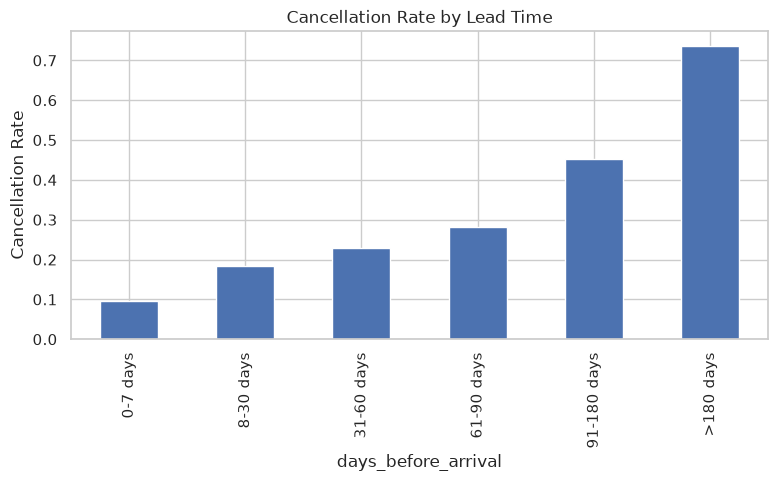

In [101]:
bins = [-1, 7, 30, 60, 90, 180, float("inf")]
labels = [
    "0-7 days",
    "8-30 days",
    "31-60 days",
    "61-90 days",
    "91-180 days",
    ">180 days"
]

lead_time_group = pd.cut(
    train_df["days_before_arrival"],
    bins=bins,
    labels=labels
)

summary = (
    train_df.groupby(
        lead_time_group,
        observed=True
    )["is_canceled"]
    .agg(
        total="count",
        cancellation_rate="mean"
    )
)

print("\n=========== Statistik cancel berdasarkan durasi hari sebelum datang ===========")
display(summary)

summary["cancellation_rate"].plot(
    kind="bar",
    figsize=(9, 4),
    title="Cancellation Rate by Lead Time"
)

plt.ylabel("Cancellation Rate")
plt.show()

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [102]:
TARGET = "is_canceled"
ID_COL = "id"

X = train_df.drop(columns=[TARGET, ID_COL])
y = train_df[TARGET].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=CFG.SEED,
    stratify=y
)

X_test = test_df.drop(columns=[ID_COL]).copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (21898, 17)
Validation: (5475, 17)
Testing: (6844, 17)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [103]:
FEATURE_COLS = X_train.columns.tolist()

NUMERIC_COLS = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

CATEGORICAL_COLS = [
    "meal_package",
    "room_category",
    "booking_channel"
]

BINARY_COLS = [
    "needs_parking",
    "is_returning_guest"
]

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [104]:
X_train = X_train.copy()
X_val = X_val.copy()
X_test = test_df.drop(columns=["id"]).copy()

def clean_missing_values(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    adults_median = X_train["num_adults"].median()
    childs_median = X_train["num_children"].median()
    days_median = X_train["days_before_arrival"].median()
    room_rate_medians = X_train.groupby("room_category")["nightly_rate_idr"].median().to_dict()
    global_rate_median = X_train["nightly_rate_idr"].median()

    for df in [X_train] + X_tests:
        # Save into a new feature for these missing attribute
        df["special_requests_is_missing"] = df["special_requests"].isna().astype(int)
        df["nightly_rate_is_missing"] = df["nightly_rate_idr"].isna().astype(int)

        # Fill missing binary features with 0
        df["special_requests"] = df["special_requests"].fillna(0)
        df["needs_parking"] = df["needs_parking"].fillna(0)

        # Fill categorical nulls with "Unknown" 
        df["meal_package"] = df["meal_package"].astype("object").fillna("Unknown")
        df["room_category"] = df["room_category"].astype("object").fillna("Unknown")

        # Fill numeric features using X_train medians 
        df["num_adults"] = df["num_adults"].fillna(adults_median)
        df["num_children"] = df["num_children"].fillna(childs_median)
        df["days_before_arrival"] = df["days_before_arrival"].fillna(days_median)

        # Fill price rate using X_train median grouped based on by room_category for rate
        mapped_medians = df["room_category"].map(room_rate_medians).fillna(global_rate_median)
        df["nightly_rate_idr"] = df["nightly_rate_idr"].fillna(mapped_medians)
    
    return X_train, X_tests

X_train, (X_val, X_test) = clean_missing_values(X_train, [X_val, X_test])

# Verification
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert df.isna().sum().sum() == 0, f"Missing values imputation failed for {name}!"

BINARY_COLS += ["special_requests_is_missing", "nightly_rate_is_missing"]
FEATURE_COLS += ["special_requests_is_missing", "nightly_rate_is_missing"]

print("Handled missing values")

Handled missing values


### Duplicates

This part covers repeated records.

In [105]:
# Since ID is dropped so we can just drop based on exact row duplicates on X_train

def clean_duplicates(X_train, y_train):
    X_train = X_train.drop_duplicates(keep="first").copy()
    y_train = y_train.loc[X_train.index].copy()
    return X_train, y_train

X_train, y_train = clean_duplicates(X_train, y_train)
assert X_train.duplicated().sum() == 0, "Duplicates still exist"
assert len(X_train) == len(y_train), "Duplicate handling failed causing mismatch"

print("Handled duplicates")

Handled duplicates


### Outliers

This part covers values far from the rest of the data.

In [106]:
outlier_summary = X_train[NUMERIC_COLS].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

print("============== Outlier summary (before) ==============")
display(
    outlier_summary[
        ["min", "1%", "25%", "50%", "75%", "99%", "max"]
    ]
)

# Only nightly_rate_idr that has significant outlier, other attributes that has outlier correlate with the cancellation rate so better not clip it
def clean_outliers(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    rate_upper_cap = X_train["nightly_rate_idr"].quantile(0.999)
    for df in [X_train] + X_tests:
        df["nightly_rate_idr"] = df["nightly_rate_idr"].clip(upper=rate_upper_cap)

    return X_train, X_tests, rate_upper_cap

X_train, (X_val, X_test), rate_upper_cap = clean_outliers(X_train, [X_val, X_test])

for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert (df["nightly_rate_idr"] > rate_upper_cap).sum() == 0, f"Uncapped rate outliers remain in {name}!"

print("============== Outlier summary (after) ==============")
outlier_summary = X_train[NUMERIC_COLS].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T

display(
    outlier_summary[
        ["min", "1%", "25%", "50%", "75%", "99%", "max"]
    ]
)

============== Outlier summary (before) ==============


,min,1%,25%,50%,75%,99%,max
num_adults,0.0,1.0,2.0,2.0,2.0,3.0,4.0
num_children,0.0,0.0,0.0,0.0,0.0,2.0,10.0
weekend_nights,0.0,0.0,0.0,1.0,2.0,2.0,7.0
weekday_nights,0.0,0.0,1.0,2.0,3.0,6.0,17.0
days_before_arrival,0.0,0.0,18.0,57.0,121.0,342.0,448.0
arrival_year,2023.0,2023.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_month,1.0,1.0,5.0,8.0,10.0,12.0,12.0
arrival_day,1.0,1.0,8.0,16.0,23.0,31.0,31.0
prior_cancellations,0.0,0.0,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,4.0,58.0


============== Outlier summary (after) ==============


,min,1%,25%,50%,75%,99%,max
num_adults,0.0,1.0,2.0,2.0,2.0,3.0,4.0
num_children,0.0,0.0,0.0,0.0,0.0,2.0,10.0
weekend_nights,0.0,0.0,0.0,1.0,2.0,2.0,7.0
weekday_nights,0.0,0.0,1.0,2.0,3.0,6.0,17.0
days_before_arrival,0.0,0.0,18.0,57.0,121.0,342.0,448.0
arrival_year,2023.0,2023.0,2024.0,2024.0,2024.0,2024.0,2024.0
arrival_month,1.0,1.0,5.0,8.0,10.0,12.0,12.0
arrival_day,1.0,1.0,8.0,16.0,23.0,31.0,31.0
prior_cancellations,0.0,0.0,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,4.0,58.0


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [107]:
NONNEGATIVE_COLS = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

def clean_domain_errors(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    for df in [X_train] + X_tests:
        # Keep the zero domain error as a binary attribute so it still can be detected by model
        df["is_zero_guests"] = ((df["num_adults"] + df["num_children"]) == 0).astype(int)
        df["is_zero_nights"] = ((df["weekend_nights"] + df["weekday_nights"]) == 0).astype(int)
        df["is_zero_rate"] = (df["nightly_rate_idr"] == 0).astype(int)

        # If a booking does not have guest then assume there should be at least one guess (adult) but missing
        df.loc[(df["num_adults"] + df["num_children"]) == 0, "num_adults"] = 1.0

        # If a booking does not have any nights, assume there should be one nights but missing
        df.loc[(df["weekend_nights"] + df["weekday_nights"]) == 0, "weekday_nights"] = 1

        # If there is a negative value in non-negative attribute then just clip it to zero
        for col in NONNEGATIVE_COLS:
            df[col] = df[col].clip(lower=0)

    return X_train, X_tests

X_train, (X_val, X_test) = clean_domain_errors(X_train, [X_val, X_test])

# Validate again
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert ((df["num_adults"] + df["num_children"]) <= 0).sum() == 0, f"Domain error still found in {name}"
    assert ((df["weekend_nights"] + df["weekday_nights"]) <= 0).sum() == 0, f"Domain error still found in {name}"
    assert (df[NONNEGATIVE_COLS] < 0).sum().sum() == 0, f"Domain error still found in {name}"
    assert (~df["arrival_month"].between(1, 12)).sum() == 0, f"Domain error still found in {name}"
    assert (~df["arrival_day"].between(1, 31)).sum() == 0, f"Domain error still found in {name}"
    assert (df["nightly_rate_idr"] > rate_upper_cap).sum() == 0, f"Domain error still found in {name}"

print("No data domain error detected")

No data domain error detected


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [108]:
def construct_features(X_train, X_tests):
    X_train = X_train.copy()
    X_tests = [df.copy() for df in X_tests]

    room_median_rates = X_train.groupby("room_category")["nightly_rate_idr"].median().to_dict()

    for df in [X_train] + X_tests:
        # Booking duration related stuff
        df["total_nights"] = df["weekend_nights"] + df["weekday_nights"]
        df["weekend_night_ratio"] = df["weekend_nights"] / df["total_nights"]
        df["is_weekend_only"] = ((df["weekend_nights"] > 0) & (df["weekday_nights"] == 0)).astype(int)
        df["is_weekday_only"] = ((df["weekday_nights"] > 0) & (df["weekend_nights"] == 0)).astype(int)

        # Booking guest related stuff
        df["total_guests"] = df["num_adults"] + df["num_children"]
        df["is_family"] = (df["num_children"] > 0).astype(int)
        df["children_ratio"] = df["num_children"] / df["total_guests"]

        # Money and price related stuff
        df["total_booking_value"] = df["total_nights"] * df["nightly_rate_idr"]
        df["rate_per_guest"] = df["nightly_rate_idr"] / df["total_guests"]

        expected_room_price_rate = df["room_category"].map(room_median_rates).fillna(X_train["nightly_rate_idr"].median())
        df["guess_paid_ratio"] = df["nightly_rate_idr"] / expected_room_price_rate # Ratio of how close the guess paid relative to the room price median

        # Guest history and guest requirement related stuff
        df["has_special_request"] = (df["special_requests"] > 0).astype(int)
        df["total_prior_bookings"] = df["prior_cancellations"] + df["prior_completed_bookings"]
        df["prior_cancel_rate"] = df["prior_cancellations"] / (df["total_prior_bookings"] + 1)
        df["net_completed_bookings"] = df["prior_completed_bookings"] - df["prior_cancellations"]
        df["commitment_score"] = (df["has_special_request"] + (df["needs_parking"] > 0).astype(int) + df["is_returning_guest"])

        # Category based on days before arrival, visualisation suggest this has high correlation
        df["arrival_time_rank"] = pd.cut(
            df["days_before_arrival"], bins=[-1, 7, 30, 60, 90, 180, np.inf], labels=[0, 1, 2, 3, 4, 5]
        ).astype(int)
        df["is_arrival_late"] = (df["days_before_arrival"] <= 7).astype(int)
        df["is_arrival_early"] = (df["days_before_arrival"] > 180).astype(int)

    return X_train, X_tests

X_train, (X_val, X_test) = construct_features(X_train, [X_val, X_test])


# Verify nno NaN or infinity in all new features
for name, df in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert df.isna().sum().sum() == 0, f"Found NaN in {name}"
    num_array = df.select_dtypes(include=[np.number]).to_numpy()
    assert not np.isinf(num_array).any(), f"Infinity found in {name}"

new_numeric_cols = [
    "total_nights",
    "weekend_night_ratio",
    "total_guests",
    "children_ratio",
    "total_booking_value",
    "rate_per_guest",
    "guess_paid_ratio",
    "total_prior_bookings",
    "prior_cancel_rate",
    "net_completed_bookings",
    "commitment_score",
    "arrival_time_rank",
]

new_binary_cols = [
    "is_weekend_only",
    "is_weekday_only",
    "is_family",
    "has_special_request",
    "is_arrival_late",
    "is_arrival_early",
]


NUMERIC_COLS += new_numeric_cols
BINARY_COLS += new_binary_cols
FEATURE_COLS += new_numeric_cols + new_binary_cols

print(f"Total features after attribute construction: {X_train.shape[1]}")
print(f"New numeric attributes: {new_numeric_cols}")
print(f"New binary attributes: {new_binary_cols}")

Total features after attribute construction: 40
New numeric attributes: ['total_nights', 'weekend_night_ratio', 'total_guests', 'children_ratio', 'total_booking_value', 'rate_per_guest', 'guess_paid_ratio', 'total_prior_bookings', 'prior_cancel_rate', 'net_completed_bookings', 'commitment_score', 'arrival_time_rank']
New binary attributes: ['is_weekend_only', 'is_weekday_only', 'is_family', 'has_special_request', 'is_arrival_late', 'is_arrival_early']


In [109]:
# See the new feature correlation
print("Feature correlation with target classification")
correlation = X_train[NUMERIC_COLS + BINARY_COLS].corrwith(y_train).sort_values()
display(correlation.to_frame(name="correlation_with_is_canceled"))

Feature correlation with target classification


,correlation_with_is_canceled
commitment_score,-0.265728
special_requests,-0.251435
has_special_request,-0.240454
is_arrival_late,-0.206247
is_returning_guest,-0.106683
needs_parking,-0.083628
total_prior_bookings,-0.059003
prior_completed_bookings,-0.058432
net_completed_bookings,-0.055263
is_weekday_only,-0.045622


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [110]:
# Done later in pipeline immediately

### Encoding

This part covers the numeric representation of categorical attributes.

In [111]:
# Done later in pipeline immediately

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [112]:
# Done later in pipeline immediately

## Class Balance

This part covers the proportion of each class in the training data.

In [113]:
# Nothing to be one here I think, because the class imbalance is not significant

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [114]:
# Nothing to be done here I think

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [115]:
def build_preprocessor(scaling="standard", pca_components=None):
    if pca_components is not None and scaling == "none":
        raise ValueError("Scaling must be enabled ('standard' or 'minmax') before applying PCA.")

    def make_scaler():
        if scaling == "standard":
            return StandardScaler()
        elif scaling == "minmax":
            return MinMaxScaler()
        elif scaling == "none":
            return "passthrough"
        else:
            raise ValueError(f"Unknown scaling: {scaling}")

    numeric_features = [col for col in NUMERIC_COLS if col != "special_requests"]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", make_scaler())
    ])

    special_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", make_scaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    binary_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ])

    column_transformer = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("special", special_pipeline, ["special_requests"]),
        ("categorical", categorical_pipeline, CATEGORICAL_COLS),
        ("binary", binary_pipeline, BINARY_COLS)
    ])

    pca_step = (
        PCA(n_components=pca_components, random_state=CFG.SEED) if pca_components is not None
        else "passthrough"
    )

    return Pipeline([
        ("features", column_transformer),
        ("pca", pca_step)
    ])


preprocessors = {
    "knn": build_preprocessor("standard", pca_components=0.95),
    "decision_tree": build_preprocessor("none", pca_components=None),
    "logistic_regression": build_preprocessor("standard", pca_components=0.95),
    "svm": build_preprocessor("standard", pca_components=0.95),
    "naive_bayes": build_preprocessor("none", pca_components=None),
}

In [116]:
preprocessors = {
    "knn": build_preprocessor("standard"),
    "decision_tree": build_preprocessor("none"),
    "logistic_regression": build_preprocessor("standard"),
    "svm": build_preprocessor("standard"),
    "naive_bayes": build_preprocessor("none")
}

In [117]:
processed_data = {}

for name, preprocessor in preprocessors.items():
    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    processed_data[name] = {
        "train": X_train_processed,
        "val": X_val_processed,
        "test": X_test_processed,
        "preprocessor": preprocessor
    }

    print(
        f"{name}: "
        f"train={X_train_processed.shape}, "
        f"val={X_val_processed.shape}, "
        f"test={X_test_processed.shape}"
    )

knn: train=(21837, 52), val=(5475, 52), test=(6844, 52)
decision_tree: train=(21837, 52), val=(5475, 52), test=(6844, 52)
logistic_regression: train=(21837, 52), val=(5475, 52), test=(6844, 52)
svm: train=(21837, 52), val=(5475, 52), test=(6844, 52)
naive_bayes: train=(21837, 52), val=(5475, 52), test=(6844, 52)


In [123]:
X_train_knn = processed_data["knn"]["train"]
X_val_knn = processed_data["knn"]["val"]

dtl_feature_names = [name.split("__", 1)[-1] for name in preprocessors["decision_tree"].named_steps["features"].get_feature_names_out()]
X_train_dtl = processed_data["decision_tree"]["train"]
X_val_dtl = processed_data["decision_tree"]["val"]

X_train_lr = processed_data["logistic_regression"]["train"]
X_val_lr = processed_data["logistic_regression"]["val"]

X_train_svm = processed_data["svm"]["train"]
X_val_svm = processed_data["svm"]["val"]

X_train_nb = processed_data["naive_bayes"]["train"]
X_val_nb = processed_data["naive_bayes"]["val"]

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [119]:
knn = KNN(k=5, metric="euclidean")
knn.fit(X_train_knn, y_train)

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

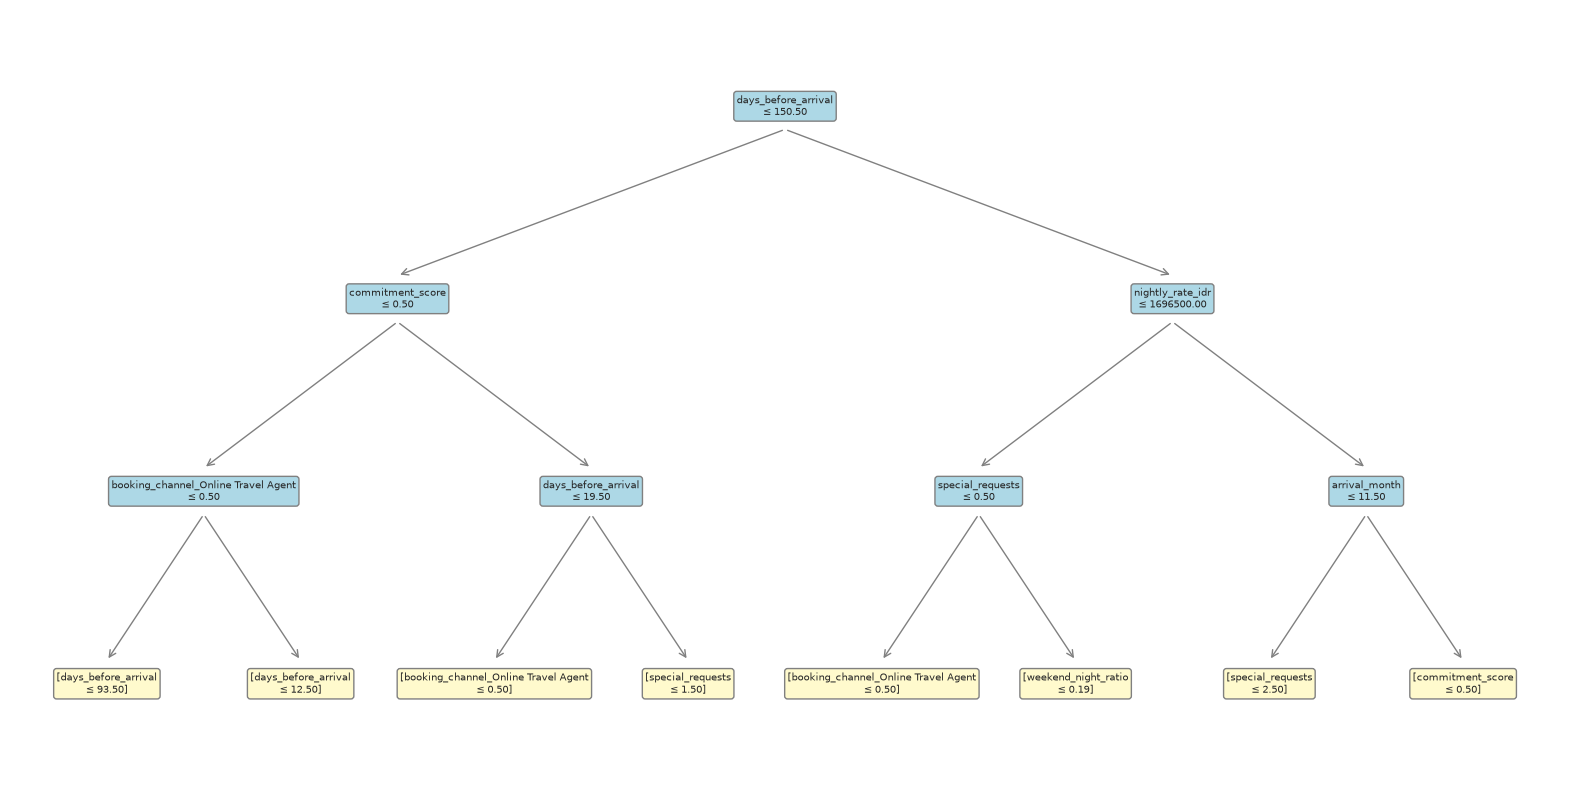

In [124]:
dtl = DTL(max_depth=5)
dtl.fit(X_train_dtl, y_train)

fig = dtl.viz(top_n=3, feature_names=dtl_feature_names, class_names=["not_canceled", "canceled"])
plt.show()

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [246]:
logistic = LR(record=True, dashboard_path="output/logreg_base_dashboard.html")
logistic.fit(X_train_lr, y_train)

output/logreg_base_dashboard.html
LogReg dashboard: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/logreg_base_dashboard.html


## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [126]:
svc = CustomSVC(random_state=CFG.SEED)
svc.fit(X_train_svm, y_train)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [127]:
naive_bayes = NaiveBayes()
naive_bayes.fit(X_train_nb, y_train)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [133]:
print("Training accuracy DTL:", dtl.score(X_val_dtl, y_val))
print("Training accuracy LR:", logistic.score(X_val_lr, y_val))
print("Training accuracy NB:", naive_bayes.score(X_val_nb, y_val))
print("Training accuracy KNN:", knn.score(X_val_knn, y_val))
print("Training accuracy SVM:", svc.score(X_val_svm, y_val))

Training accuracy DTL: 0.8189954337899543
Training accuracy LR: 0.7990867579908676
Training accuracy NB: 0.703744292237443
Training accuracy KNN: 0.8339726027397261
Training accuracy SVM: 0.834337899543379


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [138]:
def get_subsample(X_train, y_train, X_val, y_val, n_train=4000, n_val=1500, seed=CFG.SEED):
    if n_train is None or n_train >= len(X_train):
        return X_train, y_train, X_val, y_val

    X_train_sub, _, y_train_sub, _ = train_test_split(X_train, y_train, train_size=n_train, stratify=y_train, random_state=seed)
    if n_val is not None and n_val < len(X_val):
        X_val_sub, _, y_val_s, _ = train_test_split(X_val, y_val, train_size=n_val, stratify=y_val, random_state=seed)
    else:
        X_val_sub, y_val_s = X_val, y_val

    return X_train_sub, y_train_sub, X_val_sub, y_val_s

In [139]:
def tuning(
    model,
    grid,
    X_train,
    y_train,
    X_val,
    y_val,
    patience_threshold=None,
    fit_best=True,
    verbose=False
):
    param = list(grid.keys())
    val = list(grid.values())

    best_score = -np.inf
    best_params = {}

    for p in product(*val):
        params = dict(zip(param, p))

        # Initialize new model
        m = model.__class__(**params)

        # Train using training data
        m.fit(X_train, y_train)

        # Evaluate using validation data
        score = m.score(X_val, y_val)

        if verbose:
            print(f"Current: {score:.4f} - {params}")

        if score > best_score:
            best_score = score
            best_params = params

            print(f"New best: {best_score:.4f} - {best_params}")

        # Optional early stopping of hyperparameter search
        if (
            patience_threshold is not None
            and best_score >= 1 - patience_threshold
        ):
            break

    print(f"\nBest score : {best_score:.4f}")
    print(f"Best params: {best_params}")

    best_model = model.__class__(**best_params)
    if fit_best:
        best_model.fit(X_train, y_train)

    return best_model, (best_score, best_params)

New best: 0.7813 - {'max_depth': 3, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8237 - {'max_depth': 5, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8243 - {'max_depth': 5, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8303 - {'max_depth': 7, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8313 - {'max_depth': 7, 'criterion': 'gini', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8337 - {'max_depth': 7, 'criterion': 'gini', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8343 - {'max_depth': 7, 'criterion': 'gini', 'min_samples_split': 20, 'min_samples_leaf': 5}
New best: 0.8377 - {'max_depth': 10, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 1}
New best: 0.8387 - {'max_depth': 10, 'criterion': 'entropy', 'min_samples_split': 2, 'min_samples_leaf': 5}
New best: 0.8410 - {'max_depth': 10, 'crite

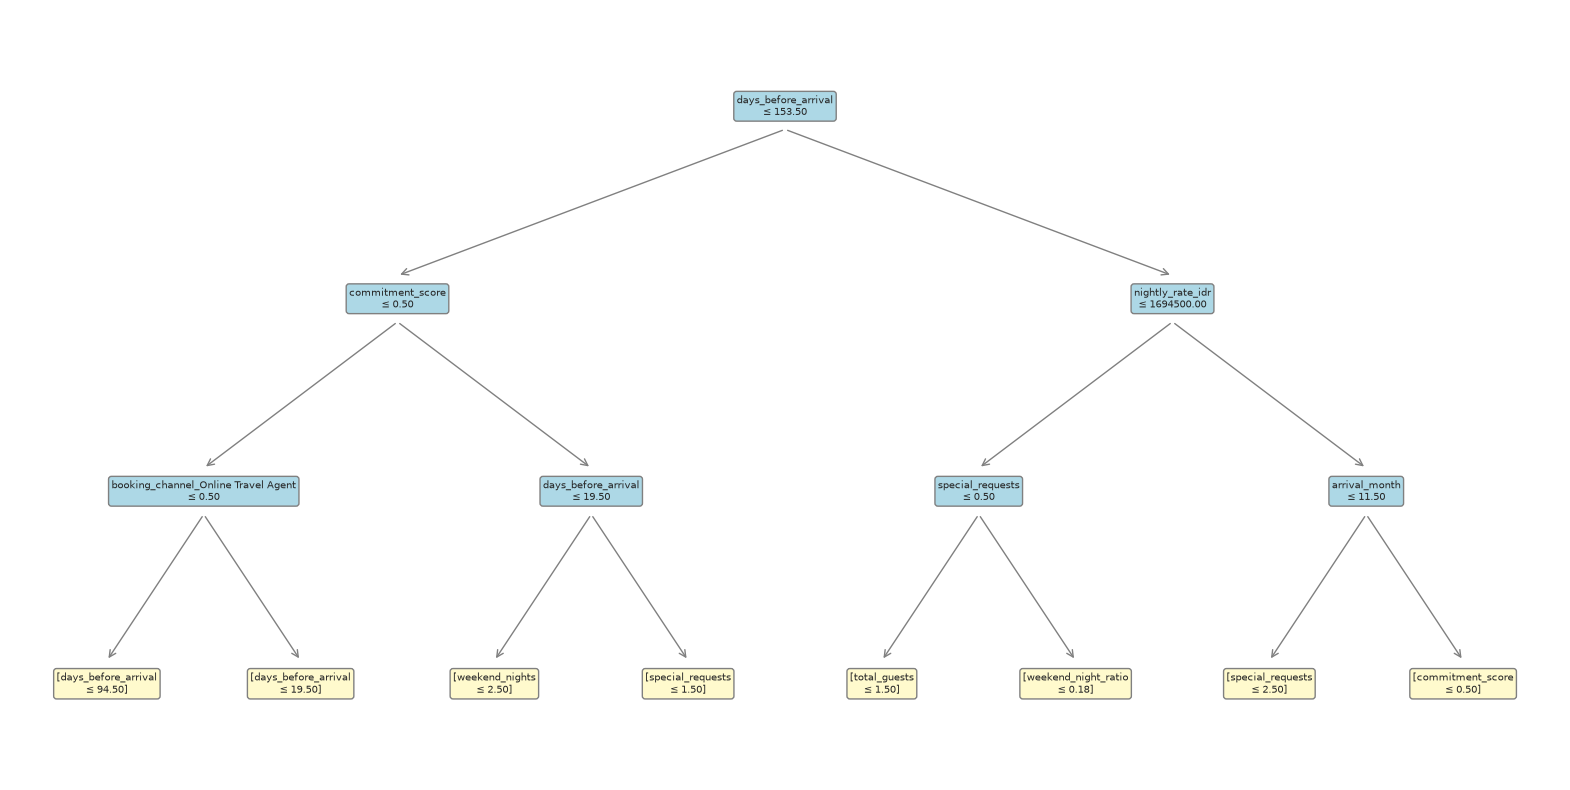

In [142]:
dtl_params = {
    'max_depth':         [3, 5, 7, 10, None],
    'criterion':         ['entropy', 'gini'],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf':  [1, 5, 10, 20],
}

# Take sample for hyperparameter tuning for faster time
X_train_dtl_sub, y_train_dtl_sub, X_val_dtl_sub, y_val_dtl_sub = get_subsample(X_train_dtl, y_train, X_val_dtl, y_val, n_train=10000, n_val=3000)

tuned_dtl, _ = tuning(dtl, dtl_params, X_train_dtl_sub, y_train_dtl_sub, X_val_dtl_sub, y_val_dtl_sub)

fig = tuned_dtl.viz(top_n=3, feature_names=dtl_feature_names, class_names=["not_canceled", "canceled"])
plt.show()

In [143]:
lr_params = {
    'rate': [0.001, 0.01, 0.1, 1.0],
    'epochs': [100, 500, 1000],
    'penalty': ['l2', None],
}

# Take sample for hyperparameter tuning for faster time
X_train_lr_sub, y_train_lr_sub, X_val_lr_sub, y_val_lr_sub = get_subsample(X_train_lr, y_train, X_val_lr, y_val, n_train=10000, n_val=3000)

tuned_lr, _ = tuning(logistic, lr_params, X_train_lr_sub, y_train_lr_sub, X_val_lr_sub, y_val_lr_sub)


New best: 0.8033 - {'rate': 0.001, 'epochs': 100, 'penalty': 'l2'}
New best: 0.8047 - {'rate': 0.001, 'epochs': 100, 'penalty': None}
New best: 0.8060 - {'rate': 0.001, 'epochs': 1000, 'penalty': None}

Best score : 0.8060
Best params: {'rate': 0.001, 'epochs': 1000, 'penalty': None}


In [144]:
nb_params = {
    'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3],
    'alpha': [0.1, 0.5, 1.0, 2.0],
}

tuned_nb, _ = tuning(naive_bayes, nb_params, X_train_nb, y_train, X_val_nb, y_val)

New best: 0.7037 - {'var_smoothing': 1e-09, 'alpha': 0.1}

Best score : 0.7037
Best params: {'var_smoothing': 1e-09, 'alpha': 0.1}


In [145]:
knn_params = {
    'k': [1, 3, 5, 7, 9],
    'metric': ["manhattan", "euclidean"]
}

# Take sample for hyperparameter tuning for faster time
X_train_knn_sub, y_train_knn_sub, X_val_knn_sub, y_val_knn_sub = get_subsample(X_train_knn, y_train, X_val_knn, y_val, n_train=4000, n_val=1500)

tuned_knn, _ = tuning(knn, knn_params, X_train_knn_sub, y_train_knn_sub, X_val_knn_sub, y_val_knn_sub)

New best: 0.7767 - {'k': 1, 'metric': 'manhattan'}
New best: 0.7840 - {'k': 3, 'metric': 'euclidean'}
New best: 0.8013 - {'k': 5, 'metric': 'manhattan'}
New best: 0.8047 - {'k': 7, 'metric': 'manhattan'}
New best: 0.8067 - {'k': 9, 'metric': 'manhattan'}

Best score : 0.8067
Best params: {'k': 9, 'metric': 'manhattan'}


In [146]:
all_svm_params = [
    { 'kernel': ['linear'], 'C': [0.1, 1.0, 10.0], 'random_state': [42], 'cache_size': [4000] },
    { 'kernel': ['rbf'], 'C': [0.1, 1.0, 10.0], 'gamma': ['scale', 0.01, 0.1], 'random_state': [42], 'cache_size': [4000] },
    { 'kernel': ['poly'],  'C': [0.1, 1.0, 10.0],  'degree': [2, 3], 'gamma': ['scale', 0.1],  'coef0': [0.0, 1.0], 'random_state': [42], 'cache_size': [4000] }
]

# Take sample for hyperparameter tuning for faster time
X_train_svm_sub, y_train_svm_sub, X_val_svm_sub, y_val_svm_sub = get_subsample(X_train_svm, y_train, X_val_svm, y_val, n_train=4000, n_val=1500)

overall_best_param = None
overall_best_score = 0
for svm_params in all_svm_params:
    tuned_svm, (best_score, best_param) = tuning(svc, svm_params, X_train_svm_sub, y_train_svm_sub, X_val_svm_sub, y_val_svm_sub, fit_best=False, verbose=True)
    if best_score > overall_best_score:
        overall_best_score = best_score
        overall_best_param = best_param
    print('\n\n')

tuned_svm = CustomSVC(**overall_best_param)
tuned_svm.fit(X_train_svm_sub, y_train_svm_sub)
print(f"Overall best: {overall_best_score:.4f} - {overall_best_param}")

Current: 0.7947 - {'kernel': 'linear', 'C': 0.1, 'random_state': 42, 'cache_size': 4000}
New best: 0.7947 - {'kernel': 'linear', 'C': 0.1, 'random_state': 42, 'cache_size': 4000}
Current: 0.7853 - {'kernel': 'linear', 'C': 1.0, 'random_state': 42, 'cache_size': 4000}
Current: 0.7727 - {'kernel': 'linear', 'C': 10.0, 'random_state': 42, 'cache_size': 4000}

Best score : 0.7947
Best params: {'kernel': 'linear', 'C': 0.1, 'random_state': 42, 'cache_size': 4000}



Current: 0.7933 - {'kernel': 'rbf', 'C': 0.1, 'gamma': 'scale', 'random_state': 42, 'cache_size': 4000}
New best: 0.7933 - {'kernel': 'rbf', 'C': 0.1, 'gamma': 'scale', 'random_state': 42, 'cache_size': 4000}
Current: 0.7840 - {'kernel': 'rbf', 'C': 0.1, 'gamma': 0.01, 'random_state': 42, 'cache_size': 4000}
Current: 0.7880 - {'kernel': 'rbf', 'C': 0.1, 'gamma': 0.1, 'random_state': 42, 'cache_size': 4000}
Current: 0.8167 - {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'random_state': 42, 'cache_size': 4000}
New best: 0.8167 - {

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [147]:
dtl_scikit = DecisionTreeClassifier()
dtl_scikit.fit(X_train_dtl,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [148]:
logistic_scikit = LogisticRegression()
logistic_scikit.fit(X_train_lr,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [150]:
naive_scikit = GaussianNB()
naive_scikit.fit(X_train_nb, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[14682., 7155.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.67,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.268e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,52
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 52)","[[1.82,0.1 ,0.78,...,0.53,0.2 ,0.05], [1.91,0.12,0.89,...,0.27,0.05,0.32]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 52)","[[12685.24,12685.12,12685.69,...,12685.22,12685.13,12685.02], [12685.2 ,12685.16,12685.83,...,12685.17,12685.01,12685.19]]"


In [151]:
knn_scikit = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn_scikit.fit(X_train_knn, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [152]:
svc_scikit = SVC()
svc_scikit.fit(X_train_svm, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [153]:
print("Training accuracy DTL-scikit", dtl_scikit.score(X_val_dtl,y_val))
print("Training accuracy LR-scikit:", logistic_scikit.score(X_val_lr, y_val))
print("Training accuracy NB-scikit:", naive_scikit.score(X_val_nb, y_val))
print("Training accuracy KNN-scikit:", knn_scikit.score(X_val_knn, y_val)) 
print("Training accuracy SVM-scikit:", svc_scikit.score(X_val_svm, y_val)) 

Training accuracy DTL-scikit 0.8202739726027397
Training accuracy LR-scikit: 0.8014611872146119
Training accuracy NB-scikit: 0.703744292237443
Training accuracy KNN-scikit: 0.8341552511415525
Training accuracy SVM-scikit: 0.8341552511415525


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->
 Sekarang build dengan data seluruhnya dan bukan training saja

In [154]:
# Get the full training and testing, drop appropriate attribute and target class
X_full = train_df.drop(columns=[TARGET, ID_COL]).copy()
y_full = train_df[TARGET].copy()
X_test_full = test_df.drop(columns=[ID_COL]).copy()
test_ids = test_df[ID_COL].copy()

# Cleaning and atribute construction of full dataset
X_full, (X_test_full,) = clean_missing_values(X_full, [X_test_full])
X_full, y_full = clean_duplicates(X_full, y_full)
X_full, (X_test_full,) = clean_domain_errors(X_full, [X_test_full])
X_full, (X_test_full,), full_rate_cap = clean_outliers(X_full, [X_test_full])
X_full, (X_test_full,) = construct_features(X_full, [X_test_full])
y_full = y_full.to_numpy()

print("Full training:", X_full.shape)
print("Test:", X_test_full.shape)
print("Target:", y_full.shape)

Full training: (27271, 40)
Test: (6844, 40)
Target: (27271,)


In [155]:
assert X_full.duplicated().sum() == 0, "Duplicates found"
assert len(X_full) == len(y_full), "X and y length mismatch"
assert len(X_test_full) == len(test_ids), "X and its test_id length mismatch"
assert list(X_full.columns) == list(X_test_full.columns), "X_train and X_test features does not match"

for name, df in [("X_full", X_full), ("X_test_full", X_test_full)]:
    assert df.isna().sum().sum() == 0, f"Missing values remain in {name}"
    assert not np.isinf(df.select_dtypes(include=[np.number]).to_numpy()).any(), f"Infinite values found in {name}"
    assert ((df["num_adults"] + df["num_children"]) <= 0).sum() == 0, f"Domain errors remain in {name}"
    assert ((df["weekend_nights"] + df["weekday_nights"]) <= 0).sum() == 0, f"Domain errors remain in {name}"
    assert (df[NONNEGATIVE_COLS] < 0).sum().sum() == 0, f"Domain errors remain in {name}"
    assert (~df["arrival_month"].between(1, 12)).sum() == 0, f"Domain errors remain in {name}"
    assert (~df["arrival_day"].between(1, 31)).sum() == 0, f"Domain errors remain in {name}"
    assert (df["nightly_rate_idr"] > full_rate_cap).sum() == 0, f"Outliers found in {name}"

print("Validation passed for full training and full test")


Validation passed for full training and full test


In [156]:
# Preprocessing configuration
MODEL_PREPROCESSING = {
    "knn": "standard",
    "decision_tree": "none",
    "logistic_regression": "standard",
    "svm": "standard",
    "naive_bayes": "none"
}

# Store processed data
final_processed_data = {}

for name, scaling in MODEL_PREPROCESSING.items():
    # Create a fresh preprocessor
    preprocessor = build_preprocessor(scaling=scaling)

    # Fit only on full training data
    X_train_processed = preprocessor.fit_transform(X_full)

    # Transform Kaggle test using fitted preprocessor
    X_test_processed = preprocessor.transform(X_test_full)

    # Store data and fitted preprocessor
    final_processed_data[name] = {
        "train": X_train_processed,
        "test": X_test_processed,
        "preprocessor": preprocessor
    }

    print(
        f"{name:20} | "
        f"train: {X_train_processed.shape} | "
        f"test: {X_test_processed.shape}"
    )

knn                  | train: (27271, 52) | test: (6844, 52)
decision_tree        | train: (27271, 52) | test: (6844, 52)
logistic_regression  | train: (27271, 52) | test: (6844, 52)
svm                  | train: (27271, 52) | test: (6844, 52)
naive_bayes          | train: (27271, 52) | test: (6844, 52)


In [157]:
for name, data in final_processed_data.items():
    Xtr = data["train"]
    Xt = data["test"]

    assert Xtr.shape[0] == len(y_full)
    assert Xt.shape[0] == len(test_df)
    assert Xtr.shape[1] == Xt.shape[1]

    assert np.isfinite(Xtr).all()
    assert np.isfinite(Xt).all()

    print(f"{name}: PASSED")

knn: PASSED
decision_tree: PASSED
logistic_regression: PASSED
svm: PASSED
naive_bayes: PASSED


In [158]:
X_train_knn_final = final_processed_data["knn"]["train"]
X_test_knn_final = final_processed_data["knn"]["test"]

X_train_dtl_final = final_processed_data["decision_tree"]["train"]
X_test_dtl_final = final_processed_data["decision_tree"]["test"]

X_train_lr_final = final_processed_data["logistic_regression"]["train"]
X_test_lr_final = final_processed_data["logistic_regression"]["test"]

X_train_nb_final = final_processed_data["naive_bayes"]["train"]
X_test_nb_final = final_processed_data["naive_bayes"]["test"]

X_train_svm_final = final_processed_data["svm"]["train"]
X_test_svm_final = final_processed_data["svm"]["test"]

In [160]:
final_knn = KNN(k=9, metric="manhattan")
final_knn.fit(X_train_knn_final, y_full)

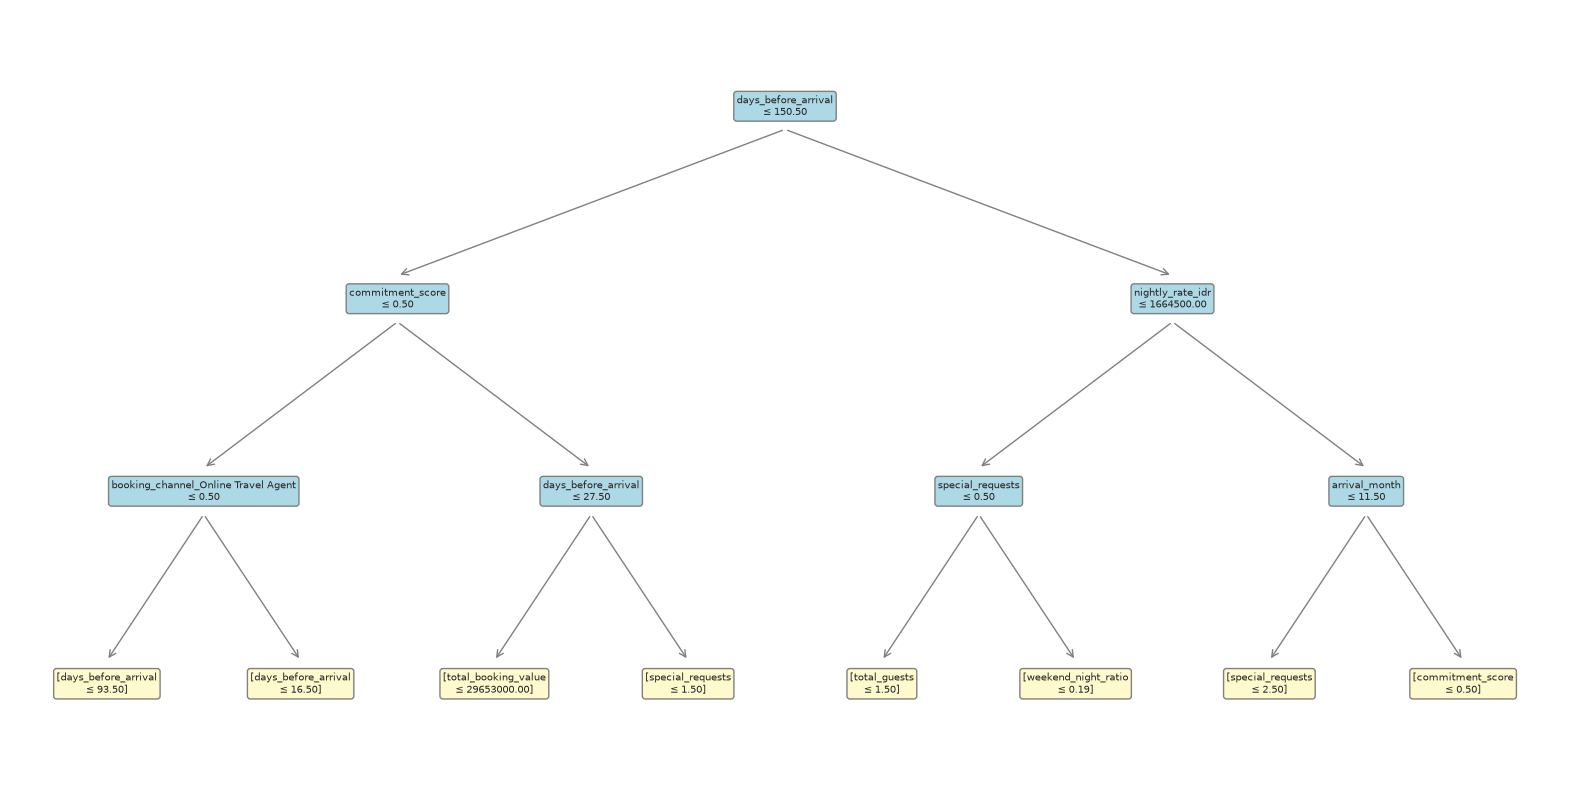

In [161]:
final_dtl = DTL(max_depth=10, criterion="gini", min_samples_split=10, min_samples_leaf=1)
final_dtl.fit(X_train_dtl_final, y_full)

fig = final_dtl.viz(top_n=3, feature_names=dtl_feature_names, class_names=["not_canceled", "canceled"])
plt.show()

In [247]:
final_lr = LR(rate=0.001, epochs=1000, penalty=None, record=True, dashboard_path="output/logreg_final_dashboard.html")
final_lr.fit(X_train_lr_final, y_full)

output/logreg_final_dashboard.html
LogReg dashboard: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/logreg_final_dashboard.html


In [163]:
final_nb = NaiveBayes(var_smoothing=1e-09, alpha=0.1)
final_nb.fit(X_train_nb_final, y_full)

In [164]:
final_svc = CustomSVC(kernel='rbf', C=1.0, gamma=0.1, random_state=CFG.SEED, cache_size=4000)
final_svc.fit(X_train_svm_final, y_full)

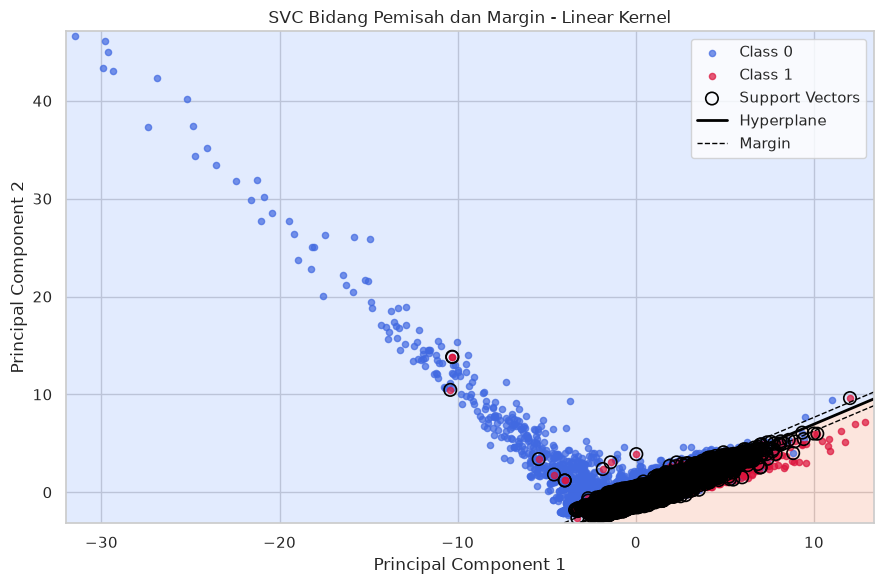

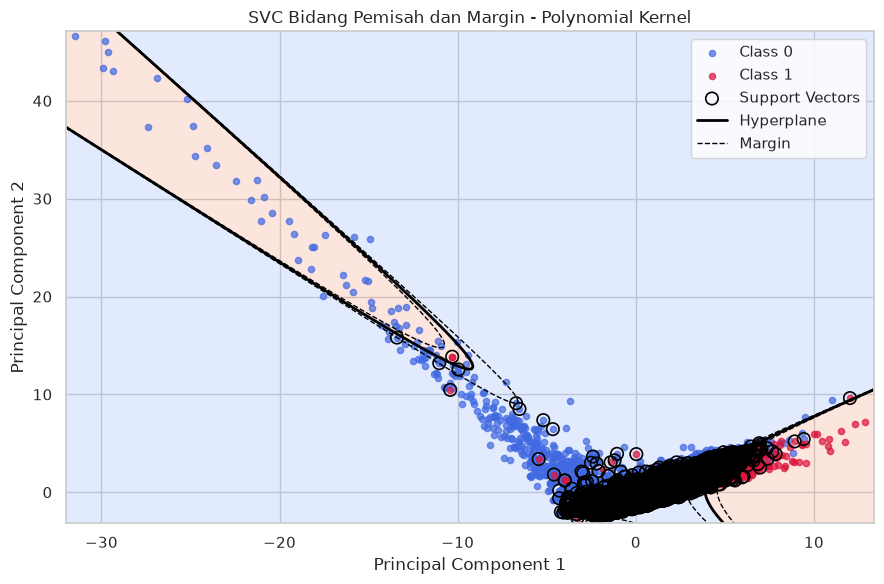

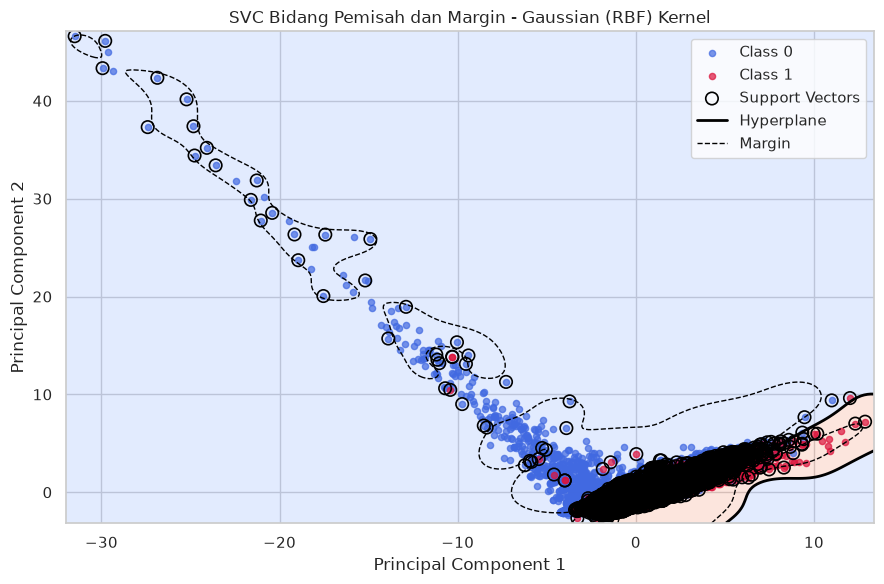

In [167]:
# Take exactly 2 features from PCA and plot the hyperplane and boundary
X_final_2d = PCA(n_components=2, random_state=CFG.SEED).fit_transform(X_train_svm_final)

kernels_to_test = [
    ('linear', 'Linear Kernel'),
    ('poly', 'Polynomial Kernel'),
    ('rbf', 'Gaussian (RBF) Kernel')
]

for kernel, name in kernels_to_test:
    svc_2d = CustomSVC(C=1.0, kernel=kernel, degree=3, gamma='scale', cache_size=4000)
    svc_2d.fit(X_final_2d, y_full)
    plot_decision_boundary(svc_2d, X_final_2d, y_full, xlabel="Principal Component 1", ylabel="Principal Component 2", title=f"SVC Bidang Pemisah dan Margin - {name}")

Prediksi akhir menggunakan model dengan hyperparameter terbaik

In [166]:
prediction_knn = final_knn.predict(X_test_knn_final)
prediction_dtl = final_dtl.predict(X_test_dtl_final)
prediction_lr = final_lr.predict(X_test_lr_final)
prediction_nb_final = final_nb.predict(X_test_nb_final)
prediction_svm = final_svc.predict(X_test_svm_final)

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [168]:
sample = pd.read_csv(
    CFG.DATA_DIR / "sample_submission.csv",
    dtype={"id": str}
)


In [169]:
submission_knn = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_knn.astype(int)
})


knn_output_dir = Path("output")
knn_output_dir.mkdir(parents=True, exist_ok=True)

knn_output_path = knn_output_dir / "submission_knn.csv"

submission_knn.to_csv(knn_output_path, index=False)

print(f"Submission saved to: {knn_output_path.resolve()}")

display(submission_knn.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_knn.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [170]:
submission_dtl = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_dtl.astype(int)
})

dtl_output_dir = Path("output")
dtl_output_dir.mkdir(parents=True, exist_ok=True)

dtl_output_path = dtl_output_dir / "submission_dtl.csv"

submission_dtl.to_csv(dtl_output_path, index=False)

print(f"Submission saved to: {dtl_output_path.resolve()}")

display(submission_dtl.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_dtl.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [171]:
submission_lr = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_dtl.astype(int)
})

lr_output_dir = Path("output")
lr_output_dir.mkdir(parents=True, exist_ok=True)

lr_output_path = lr_output_dir / "submission_lr.csv"

submission_lr.to_csv(lr_output_path, index=False)

print(f"Submission saved to: {lr_output_path.resolve()}")

display(submission_lr.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_lr.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [172]:
submission_nb = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_nb_final.astype(int)
})

nb_output_dir = Path("output")
nb_output_dir.mkdir(parents=True, exist_ok=True)

nb_output_path = nb_output_dir / "submission_nb.csv"

submission_nb.to_csv(nb_output_path, index=False)

print(f"Submission saved to: {nb_output_path.resolve()}")

display(submission_nb.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_nb.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,0
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [173]:
submission_svm = pd.DataFrame({
    "id": test_ids.astype(str),
    "is_canceled": prediction_svm.astype(int)
})

svm_output_dir = Path("output")
svm_output_dir.mkdir(parents=True, exist_ok=True)

svm_output_path = svm_output_dir / "submission_svm.csv"

submission_svm.to_csv(svm_output_path, index=False)

print(f"Submission saved to: {svm_output_path.resolve()}")

display(submission_svm.head())

Submission saved to: /home/m-fatih-im/kuliah/ai/tubes2/IF3170_G19_kagglemethis/output/submission_svm.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

In [251]:
# Taken from praktikum 2 codes

def confusion(model, X_val, y_val, name="Confusion Matrix"):
    figure, axes = plt.subplots(1, figsize=(4, 3.6))

    ConfusionMatrixDisplay.from_predictions(y_val, model.predict(X_val), ax=axes, colorbar=False)
    axes.set_title(name)

    plt.tight_layout()
    plt.show()

def error_report(model, X_val, y_val):
    tables = {}
    tables[name] = pd.DataFrame(classification_report(y_val, model.predict(X_val), output_dict=True)).T
    return pd.concat(tables)

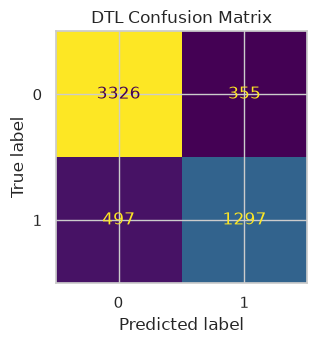

precision    recall  f1-score      support
Gaussian (RBF) Kernel 0              0.869997  0.903559  0.886461  3681.000000
                      1              0.785109  0.722965  0.752757  1794.000000
                      accuracy       0.844384  0.844384  0.844384     0.844384
                      macro avg      0.827553  0.813262  0.819609  5475.000000
                      weighted avg   0.842182  0.844384  0.842650  5475.000000

In [252]:
confusion(tuned_dtl, X_val_dtl, y_val, name="DTL Confusion Matrix")
error_report(tuned_dtl, X_val_dtl, y_val)

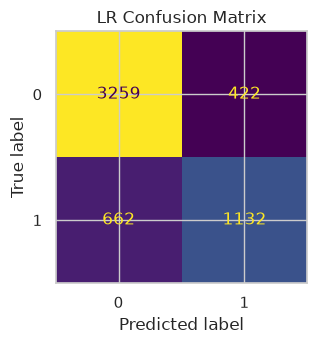

precision    recall  f1-score      support
Gaussian (RBF) Kernel 0              0.831166  0.885357  0.857406  3681.000000
                      1              0.728443  0.630992  0.676225  1794.000000
                      accuracy       0.802009  0.802009  0.802009     0.802009
                      macro avg      0.779804  0.758175  0.766815  5475.000000
                      weighted avg   0.797506  0.802009  0.798038  5475.000000

In [253]:
# LR
confusion(tuned_lr, X_val_lr, y_val, name="LR Confusion Matrix")
error_report(tuned_lr, X_val_lr, y_val)

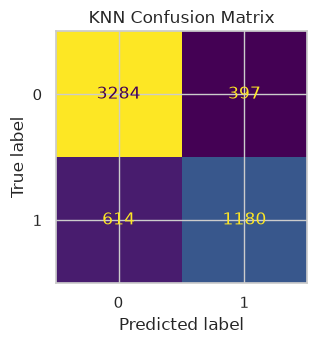

precision    recall  f1-score      support
Gaussian (RBF) Kernel 0              0.842483  0.892149  0.866605  3681.000000
                      1              0.748256  0.657748  0.700089  1794.000000
                      accuracy       0.815342  0.815342  0.815342     0.815342
                      macro avg      0.795370  0.774948  0.783347  5475.000000
                      weighted avg   0.811608  0.815342  0.812043  5475.000000

In [254]:
# KNN
confusion(tuned_knn, X_val_knn, y_val, name="KNN Confusion Matrix")
error_report(tuned_knn, X_val_knn, y_val)

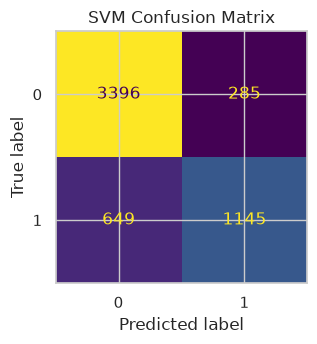

precision    recall  f1-score      support
Gaussian (RBF) Kernel 0              0.839555  0.922575  0.879110  3681.000000
                      1              0.800699  0.638239  0.710298  1794.000000
                      accuracy       0.829406  0.829406  0.829406     0.829406
                      macro avg      0.820127  0.780407  0.794704  5475.000000
                      weighted avg   0.826823  0.829406  0.823795  5475.000000

In [255]:
# SVM
confusion(tuned_svm, X_val_svm, y_val, name="SVM Confusion Matrix")
error_report(tuned_svm, X_val_svm, y_val)

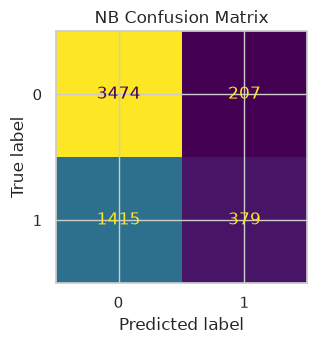

precision    recall  f1-score      support
Gaussian (RBF) Kernel 0              0.710575  0.943765  0.810735  3681.000000
                      1              0.646758  0.211260  0.318487  1794.000000
                      accuracy       0.703744  0.703744  0.703744     0.703744
                      macro avg      0.678666  0.577513  0.564611  5475.000000
                      weighted avg   0.689664  0.703744  0.649440  5475.000000

In [256]:
# NB
confusion(tuned_nb, X_val_nb, y_val, name="NB Confusion Matrix")
error_report(tuned_nb, X_val_nb, y_val)

The analysis supports each step taken in this notebook.